# 03 — Modelo de PD: regresión logística

**Objetivo.** Estimar la probabilidad de default (PD) de octubre de 2005 con una regresión
logística sobre las variables WOE de la fase anterior, medir su capacidad de discriminación y su
calibración, y dejar el modelo listo para convertirlo en scorecard. Las decisiones están en
`docs/DECISIONS.md` (ADR-012).

Se construyen dos modelos con el mismo procedimiento:

- **el campeón**, con las candidatas de ADR-011 (sin el estado de septiembre);
- **el modelo de sensibilidad** de ADR-009, con las mismas candidatas más `STATUS_SEP`. Solo sirve
  para mostrar cuánto ganaría la predicción si el estado de septiembre fuera legítimo.

**Cómo se mide sin hacer trampa.** El procedimiento completo (binning, preselección, selección de
variables y logística) se vuelve a ajustar dentro de cada uno de los 15 folds de validación
cruzada, y se mide en las filas que ese fold no vio. Así ninguna decisión ve las filas con que se
la evalúa. El conjunto de test se usa una sola vez, al final, con el modelo ya congelado.

Todos los cálculos están en `creditrisk.models`; las cifras se guardan en
`reports/metrics/pd_logistic_cv.json`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from sklearn.metrics import roc_curve

from creditrisk import plotting
from creditrisk.config import load_config
from creditrisk.data.split import load_train
from creditrisk.models.report import train_report
from creditrisk.reporting import save_metrics

plotting.apply_style()
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

NAMES = {"champion": "campeón", "sensitivity_with_status_sep": "sensibilidad (con STATUS_SEP)"}

## 1. Ajuste y validación cruzada

`train_report` ajusta los dos modelos con todo train y los mide con validación cruzada. Los
intervalos de confianza vienen de 1,000 remuestreos bootstrap estratificados.

In [2]:
train = load_train()
report, models, oof = train_report(train, n_boot=1000, seed=0)
y = train["DEFAULT"]
print(f"Filas de entrenamiento: {report['n_train_rows']:,}")
print(f"Tasa de default en train: {report['train_default_rate']:.2%}")

Filas de entrenamiento: 24,000
Tasa de default en train: 22.12%


## 2. Selección de variables

Cada candidata pasa por tres filtros, en este orden:

1. **IV** de al menos 0.02 (ADR-011).
2. **Correlación** de WOE de como mucho 0.7 con una variable más fuerte (ADR-011).
3. **Logística**: con WOE = ln(no-defaults / defaults), un bin más seguro tiene WOE mayor, así que
   todo coeficiente de un modelo de PD debe ser **negativo**. Se quita primero, de a una, cualquier
   variable con signo positivo; luego, de a una, la de mayor p-valor si supera 0.05 (ADR-012).

In [3]:
STATUS = {
    "in model": "en el modelo",
    "IV below 0.02": "IV menor que 0.02",
    "logistic: wrong sign": "logística: signo incorrecto",
    "logistic: p-value above 0.05": "logística: p-valor mayor que 0.05",
}


def status_es(text):
    return STATUS.get(text, text.replace("correlated with", "correlacionada con"))


for name, model in report["models"].items():
    table = pd.DataFrame(model["selection"]).set_index("feature")
    view = pd.DataFrame({"IV": table["iv"].round(3), "resultado": table["status"].map(status_es)})
    view.index.name = "variable"
    print(f"Modelo {NAMES[name]}: {len(model['final_features'])} variables en el modelo")
    display(view)

Modelo campeón: 5 variables en el modelo


,IV,resultado
variable,,
N_DELAY_MONTHS,0.641,en el modelo
MONTHS_SINCE_DELAY,0.630,correlacionada con N_DELAY_MONTHS
STATUS_AUG,0.550,correlacionada con N_DELAY_MONTHS
MAX_DELAY,0.531,correlacionada con N_DELAY_MONTHS
PAY_RATIO_1,0.266,en el modelo
PAY_RATIO_2,0.218,logística: p-valor mayor que 0.05
PAY_RATIO_MEAN,0.210,en el modelo
PAY_RATIO_3,0.193,logística: p-valor mayor que 0.05
LIMIT_BAL,0.175,en el modelo


Modelo sensibilidad (con STATUS_SEP): 7 variables en el modelo


,IV,resultado
variable,,
STATUS_SEP,0.873,en el modelo
N_DELAY_MONTHS,0.641,en el modelo
MONTHS_SINCE_DELAY,0.630,correlacionada con N_DELAY_MONTHS
STATUS_AUG,0.550,correlacionada con N_DELAY_MONTHS
MAX_DELAY,0.531,correlacionada con N_DELAY_MONTHS
PAY_RATIO_1,0.266,logística: p-valor mayor que 0.05
PAY_RATIO_2,0.218,en el modelo
PAY_RATIO_MEAN,0.210,en el modelo
PAY_RATIO_3,0.193,en el modelo


Las variables de utilización quedan fuera por **signo incorrecto**: una vez que el modelo conoce el
límite y el comportamiento de pago, sus bins más "seguros" pasan a asociarse con una PD mayor. No es
que la utilización no tenga relación con el default (su IV es débil pero positivo), sino que esa
relación ya está contenida en las otras variables, y un coeficiente con el signo cambiado no se
puede defender ante un comité de riesgo. Varios ratios de pago quedan fuera por p-valor: se
parecen entre sí y basta con algunos.

## 3. Coeficientes del campeón

Estimación, error estándar, p-valor e intervalo de confianza del 95% (statsmodels, máxima
verosimilitud sin penalización).

In [4]:
COLUMNS = {
    "coef": "coeficiente",
    "std_err": "error estándar",
    "z": "z",
    "p_value": "p-valor",
    "ci_low": "IC 95% inferior",
    "ci_high": "IC 95% superior",
}
for name in ["champion", "sensitivity_with_status_sep"]:
    coefs = pd.DataFrame(report["models"][name]["coefficients"]).set_index("term")
    coefs.index = coefs.index.str.replace("const", "intercepto")
    coefs.index.name = "término"
    print(f"Modelo {NAMES[name]}")
    display(coefs.rename(columns=COLUMNS).round(4))

Modelo campeón


,coeficiente,error estándar,z,p-valor,IC 95% inferior,IC 95% superior
término,,,,,,
intercepto,-1.2550,0.0169,-74.1808,0.0000,-1.2882,-1.2219
N_DELAY_MONTHS,-0.7985,0.0231,-34.5070,0.0000,-0.8439,-0.7532
PAY_RATIO_1,-0.1982,0.0375,-5.2845,0.0000,-0.2717,-0.1247
PAY_RATIO_MEAN,-0.3225,0.0444,-7.2695,0.0000,-0.4095,-0.2356
LIMIT_BAL,-0.4321,0.0421,-10.2610,0.0000,-0.5147,-0.3496
PAY_RATIO_4,-0.1241,0.0466,-2.6640,0.0077,-0.2153,-0.0328


Modelo sensibilidad (con STATUS_SEP)


,coeficiente,error estándar,z,p-valor,IC 95% inferior,IC 95% superior
término,,,,,,
intercepto,-1.2425,0.0175,-70.8617,0.0000,-1.2769,-1.2082
STATUS_SEP,-0.7442,0.0206,-36.2019,0.0000,-0.7845,-0.7039
N_DELAY_MONTHS,-0.3588,0.0286,-12.5368,0.0000,-0.4149,-0.3027
PAY_RATIO_2,-0.0909,0.0444,-2.0479,0.0406,-0.1779,-0.0039
PAY_RATIO_MEAN,-0.1442,0.0473,-3.0456,0.0023,-0.2369,-0.0514
PAY_RATIO_3,-0.1663,0.0461,-3.6122,0.0003,-0.2566,-0.0761
LIMIT_BAL,-0.4213,0.0440,-9.5769,0.0000,-0.5076,-0.3351
PAY_RATIO_4,-0.1759,0.0483,-3.6394,0.0003,-0.2707,-0.0812


**Revisión de signos.** Todos los coeficientes del campeón son negativos, como exige la convención
del WOE: más meses con atraso, un ratio de pago menor o un límite más bajo llevan a bins de WOE
negativo y, por tanto, a una PD mayor. El coeficiente más grande en valor absoluto es el de
`N_DELAY_MONTHS`, coherente con que el historial de atrasos sea la variable de mayor IV.

En el modelo de sensibilidad, el coeficiente de `N_DELAY_MONTHS` se reduce a menos de la mitad: el
estado de septiembre toma buena parte de su lugar, porque las dos describen atrasos.

## 4. Discriminación en validación cruzada

Las métricas se calculan sobre las predicciones fuera de fold: cada fila de train recibe una
predicción de un modelo que no la vio. Se muestran con su intervalo bootstrap (primera repetición),
el AUC de cada una de las tres repeticiones y el rango entre los 15 folds.

In [5]:
rows = {}
for name, model in report["models"].items():
    cv = model["cv"]
    r1 = cv["repeat_1"]
    row = {}
    for metric, label in [("auc", "AUC"), ("gini", "Gini"), ("ks", "KS"), ("pr_auc", "PR-AUC")]:
        m = r1[metric]
        row[label] = f"{m['estimate']:.3f} [{m['low']:.3f}, {m['high']:.3f}]"
    row["AUC por repetición"] = ", ".join(f"{v:.3f}" for v in cv["auc_by_repeat"].values())
    row["AUC por fold (mín-máx)"] = f"{cv['fold_auc_min']:.3f}-{cv['fold_auc_max']:.3f}"
    row["AUC en el propio train"] = f"{model['train_fit_auc']:.3f}"
    rows[NAMES[name]] = row
discrimination = pd.DataFrame(rows).T
discrimination.index.name = "modelo"
display(discrimination)

,AUC,Gini,KS,PR-AUC,AUC por repetición,AUC por fold (mín-máx),AUC en el propio train
modelo,,,,,,,
campeón,"0.718 [0.710, 0.726]","0.435 [0.419, 0.452]","0.341 [0.329, 0.356]","0.459 [0.446, 0.471]","0.718, 0.717, 0.719",0.707-0.738,0.720
sensibilidad (con STATUS_SEP),"0.761 [0.753, 0.769]","0.522 [0.506, 0.537]","0.412 [0.399, 0.427]","0.529 [0.516, 0.543]","0.761, 0.759, 0.761",0.744-0.777,0.764


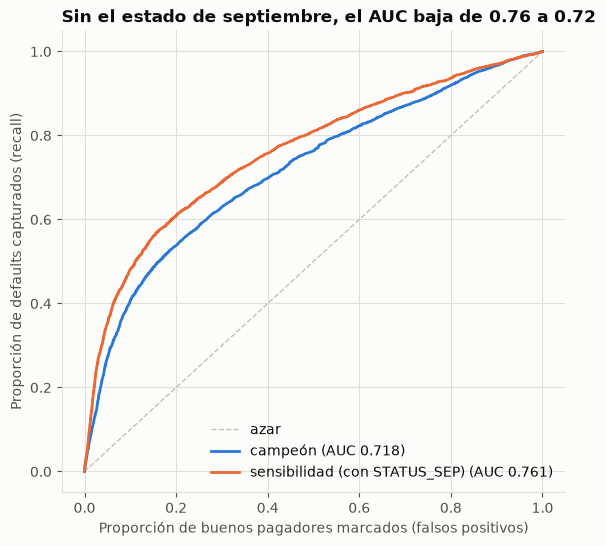

In [6]:
fig, ax = plt.subplots(figsize=(6.5, 6))
colours = {"champion": plotting.BLUE, "sensitivity_with_status_sep": plotting.ORANGE}
ax.plot([0, 1], [0, 1], color="#c3c2b7", linewidth=1, linestyle="--", label="azar")
for name, model in report["models"].items():
    fpr, tpr, _ = roc_curve(y, oof[name])  # out-of-fold predictions, repeat 1
    auc_value = model["cv"]["repeat_1"]["auc"]["estimate"]
    ax.plot(
        fpr, tpr, color=colours[name], linewidth=2, label=f"{NAMES[name]} (AUC {auc_value:.3f})"
    )
ax.set_xlabel("Proporción de buenos pagadores marcados (falsos positivos)")
ax.set_ylabel("Proporción de defaults capturados (recall)")
ax.legend(loc="lower right")
champion_auc = report["models"]["champion"]["cv"]["repeat_1"]["auc"]["estimate"]
sensitivity_auc = report["models"]["sensitivity_with_status_sep"]["cv"]["repeat_1"]["auc"][
    "estimate"
]
ax.set_title(
    f"Sin el estado de septiembre, el AUC baja de {sensitivity_auc:.2f} a {champion_auc:.2f}"
)
plotting.save_figure(fig, "pd_roc_cv")
plt.show()

El campeón discrimina de forma moderada (AUC fuera de fold de 0.718), y prácticamente igual dentro
y fuera de la muestra (0.720 en el propio train), así que no hay señales de sobreajuste. El modelo
de sensibilidad llega a 0.761: esa diferencia es lo que cuesta excluir el estado de septiembre por
la duda de fuga (ADR-009). La comparación entre ambos modelos en test, con su intervalo, se hace en
la evaluación final.

### Estabilidad de la selección entre folds

Como la selección se repite en cada fold, las variables elegidas pueden cambiar. La tabla cuenta en
cuántos de los 15 folds terminó cada variable en el modelo.

In [7]:
counts = pd.DataFrame(
    {NAMES[name]: model["cv"]["selection_counts"] for name, model in report["models"].items()}
)
counts = counts[(counts > 0).any(axis=1)].sort_values(NAMES["champion"], ascending=False)
counts.index.name = "variable"
display(counts)
for name, model in report["models"].items():
    sizes = model["cv"]["n_features_by_fold"]
    print(f"{NAMES[name]}: entre {min(sizes)} y {max(sizes)} variables por fold")

,campeón,sensibilidad (con STATUS_SEP)
variable,,
LIMIT_BAL,15.0,15
PAY_RATIO_MEAN,15.0,6
PAY_RATIO_1,14.0,5
N_DELAY_MONTHS,14.0,14
PAY_RATIO_4,11.0,15
PAY_RATIO_3,6.0,15
PAY_RATIO_2,2.0,11
PAY_RATIO_5,1.0,8
MONTHS_SINCE_DELAY,1.0,1


campeón: entre 4 y 7 variables por fold
sensibilidad (con STATUS_SEP): entre 6 y 8 variables por fold


`N_DELAY_MONTHS`, `LIMIT_BAL` y `PAY_RATIO_MEAN` entran en casi todos los folds. Los ratios de
pago mensuales se reemplazan entre sí de un fold a otro: llevan información parecida, y cuál de
ellos queda depende de pequeñas diferencias entre muestras. Eso no cambia el desempeño (el AUC por
fold es estable), pero significa que la lista exacta de variables del campeón no es única.

## 5. Calibración

Una PD calibrada coincide, en promedio, con la tasa de default observada. Se mide con el Brier
score, el intercepto y la pendiente de calibración (ideal: 0 y 1), y con la tabla por decil de PD
predicha, todo sobre las predicciones fuera de fold.

In [8]:
calibration_rows = {}
for name, model in report["models"].items():
    r1 = model["cv"]["repeat_1"]
    calibration_rows[NAMES[name]] = {
        "PD media predicha": f"{r1['mean_pd']:.2%}",
        "tasa observada": f"{r1['default_rate']:.2%}",
        "Brier": f"{r1['calibration']['brier']:.4f}",
        "intercepto de calibración": f"{r1['calibration']['calibration_intercept']:.3f}",
        "pendiente de calibración": f"{r1['calibration']['calibration_slope']:.3f}",
    }
calibration = pd.DataFrame(calibration_rows).T
calibration.index.name = "modelo"
display(calibration)

deciles = pd.DataFrame(report["models"]["champion"]["cv"]["repeat_1"]["calibration_by_decile"])
deciles_view = deciles.rename(
    columns={
        "group": "decil",
        "n": "cuentas",
        "mean_pd": "PD media",
        "default_rate": "tasa observada",
    }
).set_index("decil")
print("Campeón, por decil de PD predicha")
display(deciles_view.round(3))

,PD media predicha,tasa observada,Brier,intercepto de calibración,pendiente de calibración
modelo,,,,,
campeón,22.14%,22.12%,0.1485,-0.017,0.986
sensibilidad (con STATUS_SEP),22.13%,22.12%,0.1375,-0.011,0.991


Campeón, por decil de PD predicha


,cuentas,PD media,tasa observada
decil,,,
1,2400,0.088,0.088
2,2400,0.110,0.127
3,2400,0.125,0.112
4,2400,0.139,0.125
5,2400,0.152,0.160
6,2400,0.169,0.158
7,2400,0.183,0.197
8,2400,0.243,0.243
9,2400,0.396,0.397


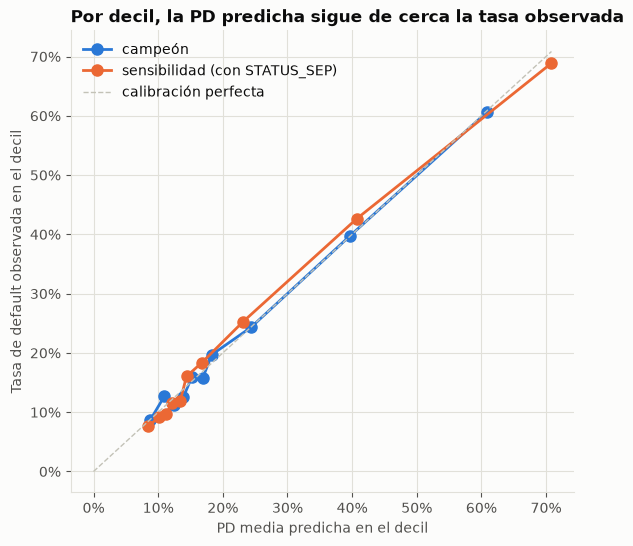

In [9]:
fig, ax = plt.subplots(figsize=(6.5, 6))
top = 0
for name, model in report["models"].items():
    table = pd.DataFrame(model["cv"]["repeat_1"]["calibration_by_decile"])
    ax.plot(
        table["mean_pd"],
        table["default_rate"],
        marker="o",
        markersize=8,
        linewidth=2,
        color=colours[name],
        label=NAMES[name],
    )
    top = max(top, table["mean_pd"].max(), table["default_rate"].max())
ax.plot(
    [0, top], [0, top], color="#c3c2b7", linewidth=1, linestyle="--", label="calibración perfecta"
)
ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.yaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.set_xlabel("PD media predicha en el decil")
ax.set_ylabel("Tasa de default observada en el decil")
ax.legend(loc="upper left")
ax.set_title("Por decil, la PD predicha sigue de cerca la tasa observada")
plotting.save_figure(fig, "pd_reliability_cv")
plt.show()

La PD media predicha coincide con la tasa observada, y la pendiente de calibración del campeón es
0.986, muy cerca de 1: las PD no son ni demasiado extremas ni demasiado planas. No hace falta
recalibrar (ADR-012). Esto es esperable porque train tiene la misma tasa de default que el archivo;
en otra población, con otra tasa, habría que recalibrar el intercepto.

## 6. Puntos de operación del campeón

Qué pasaría si se marcara para gestión a una parte de las cuentas: las de mayor PD (10%, 20% o
30% de la cartera) o todas las que superen un umbral de PD (la tasa promedio de train o 0.5). El
umbral definitivo se elige por costos en la fase de impacto de negocio; aquí solo se muestran
opciones, sobre las predicciones fuera de fold.

In [10]:
points = pd.DataFrame(report["models"]["champion"]["cv"]["repeat_1"]["operating_points"])
points["point"] = points["point"].str.replace("flag", "marcar").str.replace("PD >=", "PD ≥")
points_view = pd.DataFrame(
    {
        "umbral de PD": points["threshold"].round(3),
        "cuentas marcadas": points["flag_rate"].map("{:.1%}".format),
        "recall (defaults capturados)": points["recall"].map("{:.1%}".format),
        "precisión": points["precision"].map("{:.1%}".format),
        "falsos positivos": points["false_positive_rate"].map("{:.1%}".format),
    }
)
points_view.index = points["point"]
points_view.index.name = "punto"
display(points_view)

,umbral de PD,cuentas marcadas,recall (defaults capturados),precisión,falsos positivos
punto,,,,,
marcar 10%,0.498,10.0%,27.4%,60.6%,5.1%
marcar 20%,0.316,20.1%,45.5%,50.1%,12.9%
marcar 30%,0.199,30.0%,56.3%,41.5%,22.5%
PD ≥ 0.221208,0.221,25.5%,52.0%,45.0%,18.0%
PD ≥ 0.5,0.500,9.9%,27.1%,60.7%,5.0%


## 7. Limitaciones

- **Una sola foto.** Train y validación vienen de los mismos meses; nada de esto mide cómo se
  comportaría el modelo en otro período (ADR-003).
- **Los folds ya se usaron en la fase anterior** para excluir `AGE` y `EDUCATION`. El efecto
  posible es mínimo, pero las métricas de validación cruzada no son del todo independientes de
  esas decisiones (ADR-011).
- **Gemelos dentro de train.** 140 filas de train tienen un gemelo en las variables candidatas y
  pueden quedar en folds distintos (ADR-010), lo que favorece un poco las métricas.
- **La lista de variables no es única.** Los ratios de pago se reemplazan entre sí de un fold a
  otro; la lista del campeón es la que sale con todo train.
- **Calibración ligada a la tasa del archivo.** El 22% de default de este archivo no representa la
  cartera de un banco (`docs/DATA.md`); en otra población habría que recalibrar.
- **Supuestos de las variables.** Que los montos de septiembre y el historial de agosto a abril se
  conocieran antes de octubre es un SUPUESTO (ADR-009).

## 8. Guardado de resultados (entrenamiento)

Las cifras de este notebook y de ADR-012 salen de este archivo. La evaluación en test se guarda
aparte, en `reports/metrics/pd_logistic_test.json`, para que quede registrado cada uso del test.

In [11]:
# load_train() already checked the raw file against this hash.
data_sha256 = load_config("project")["data"]["raw_sha256"]
path = save_metrics("pd_logistic_cv", report, data_sha256)
print(f"Guardado en {path.relative_to(path.parents[2]).as_posix()}")

Guardado en reports/metrics/pd_logistic_cv.json
